In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert, gausspulse
from scipy.signal.windows import tukey

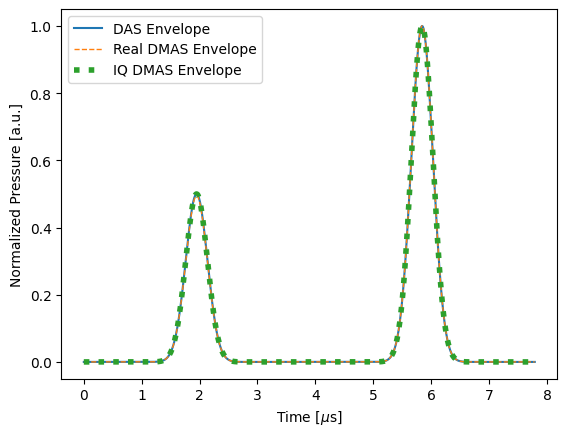

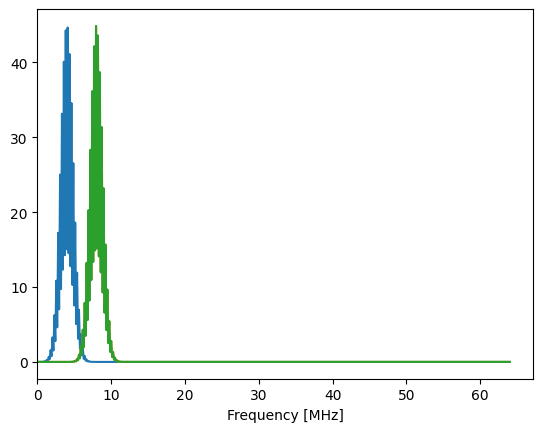

In [28]:
fc = 4E6
c = 1540
x = np.arange(0, 6, 1E3*(c/fc)/(16*4))
t = 2*1E-3*x/c

t0 = 2*1.5E-3/c
t1 = 2*4.5E-3/c
bw = 0.5
signal = 0.5*gausspulse(t-t0, fc=fc, bw=bw) + gausspulse(t-t1, fc=fc, bw=bw)
signal = hilbert(signal)


freq = np.fft.rfftfreq(len(signal), t[1]-t[0])

signal_ssr = np.sign(signal.real**2)*np.sqrt(signal.real**2)
SIGNAL_SSR = np.fft.rfft(signal_ssr)
SIGNAL_SSR[freq<fc] = 0
SIGNAL_SSR[freq>3*fc] = 0
signal_ssr = np.fft.irfft(SIGNAL_SSR, len(signal_ssr))
signal_ssr /= np.max(signal_ssr)
signal_iq  = np.exp(1j*np.angle(signal**2)) * np.sqrt(np.abs(signal)**2)

plt.figure()
# plt.plot(1E6*t, signal.real, alpha=0.25, color='black')
plt.plot(1E6*t, np.abs(signal), color='C0', label='DAS Envelope')
# plt.plot(1E6*t, signal_ssr, color='C1', alpha=0.25)
plt.plot(1E6*t, np.abs(hilbert(signal_ssr)), color='C1', lw=1, ls='--', label='Real DMAS Envelope')
plt.plot(1E6*t, np.abs(signal_iq), color='C2', ls=':', lw=4, label='IQ DMAS Envelope')
plt.xlabel("Time [$\\mu$s]")
plt.ylabel("Normalized Pressure [a.u.]")
plt.legend()
plt.show()

SIGNAL = np.fft.rfft(signal.real)
SIGNAL_SSR = np.fft.rfft(signal_ssr)
SIGNAL_IQ = np.fft.rfft(signal_iq)
plt.figure()
plt.plot(1E-6*freq, np.abs(SIGNAL))
plt.plot(1E-6*freq, np.abs(SIGNAL_SSR))
plt.plot(1E-6*freq, np.abs(SIGNAL_IQ))
plt.xlabel("Frequency [MHz]")
plt.xlim(0)
plt.show()